# ARTI 502 Deep Learning: 2nd Assignment
## Training and Testing a CNN on the CIFAR-10 Dataset using PyTorch and Transfer Learning

This notebook follows the tasks in the assignment:

1. Getting the CIFAR dataset
2. Defining the network, and the training and test functions
3. Loading the data
4. Dataset augmentation
5. Training function and tuning hyperparameters
6. Saving the model and the source code

Instead of training from random weights, I start from a ConvNeXt network that was already trained on ImageNet-22k and fine-tune it for CIFAR-10. I ran this notebook on Kaggle with two Tesla T4 GPUs.

In [1]:
import copy
import glob
import json
import math
import os
import random
import shutil
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import timm                     # pretrained models. The Kaggle image already has it, otherwise: pip install timm
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader, Subset

notebook_start = time.time()

if not torch.cuda.is_available():
    raise RuntimeError('No GPU found. This notebook would take days on a CPU, so turn on the GPU first.')

device = 'cuda'
NUM_GPUS = torch.cuda.device_count()
NUM_WORKERS = 2                 # processes that prepare the images. Use 0 on Windows

# Benchmark mode makes one GPU faster, but with two GPUs it runs again on every step and makes training very slow
torch.backends.cudnn.benchmark = NUM_GPUS == 1

print('PyTorch version:', torch.__version__, ' timm version:', timm.__version__)
print('Devices:', NUM_GPUS, 'x', torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130  timm version: 1.0.30
Devices: 2 x Tesla T4


---
# Task 1: Getting the CIFAR Dataset

PyTorch has a helper function for CIFAR-10. `DATA_PATH` is an empty folder for the dataset.

In [ ]:
DATA_PATH = '/tmp/cifar10_data'
os.makedirs(DATA_PATH, exist_ok=True)

kaggle_copy = glob.glob('/kaggle/input/**/cifar-10-python.tar.gz', recursive=True)
if kaggle_copy:
    shutil.copy(kaggle_copy[0], DATA_PATH)

train_data = torchvision.datasets.CIFAR10(DATA_PATH, train=True, download=True)
test_data = torchvision.datasets.CIFAR10(DATA_PATH, train=False, download=True)
classes = train_data.classes

print('The dataset loaded successfully')
print('Training images:', len(train_data))
print('Test images:', len(test_data))
print('Classes:', classes)

The dataset loaded successfully
Training images: 50000
Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


---
# Task 2: Defining the Network

**Transfer learning:** the weights of a pretrained network already detect useful things like edges, textures and object parts. I keep those weights as the starting point, replace the last layer with a new one for the 10 CIFAR-10 classes, and then train the whole network with a small learning rate. This is called fine-tuning.

**The network:** ConvNeXt is a modern CNN with no attention layers, so it is built from convolutions like the CNNs in this course. I use ConvNeXt-Large, which has 196 million parameters.

`nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding)`: the first parameter is the number of channels in the input, the second is the number of filters (the channels in the output) and the third is the kernel size. Stride and padding are optional.

| Part | Output channels | Details |
|---|---|---|
| Stem | 192 | 4x4 convolution with stride 4 |
| Stage 1 | 192 | 3 ConvNeXt blocks |
| Stage 2 | 384 | A 2x2 convolution with stride 2, then 3 blocks |
| Stage 3 | 768 | A 2x2 convolution with stride 2, then 27 blocks |
| Stage 4 | 1536 | A 2x2 convolution with stride 2, then 3 blocks |
| Head | 10 | Global average pooling, layer norm, linear layer (this layer is new) |

Each ConvNeXt block does a 7x7 depthwise convolution (`groups=channels`, one filter per channel), layer norm, a 1x1 convolution that makes the channels 4 times bigger, GELU, and a 1x1 convolution that brings them back, with a shortcut around all of this. timm writes the two 1x1 convolutions as linear layers, which do the same thing.

**Image size:** the pretrained network learned from 224x224 images, where objects are much bigger than in a 32x32 CIFAR-10 image. So the first layer of my model enlarges every image to 224x224 with bicubic interpolation. This happens on the GPU, after the augmentation.

**About max pooling:** ConvNeXt has no max pooling layers. It makes the images smaller with stride 2 convolutions and uses global average pooling before the classifier. In Task 5 I compare it with a small CNN that does use `nn.MaxPool2d`.

In [ ]:
class SimpleCNN(nn.Module):
    # A small CNN with convolution and max pooling layers and random starting weights, to compare with the pretrained networks
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),    # 32x32 -> 16x16
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2),    # 16x16 -> 8x8
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(),
            nn.MaxPool2d(2),    # 8x8 -> 4x4
        )
        self.classifier = nn.Linear(256 * 4 * 4, 10)

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x.flatten(1))


def build_model(name, drop_path=0.0):
    if name == 'simple_cnn':
        return SimpleCNN()
    # pretrained=True downloads the weights. num_classes=10 replaces the last layer with a new one.
    backbone = timm.create_model(name, pretrained=True, num_classes=10, drop_path_rate=drop_path)
    return nn.Sequential(nn.Upsample(size=224, mode='bicubic', align_corners=False), backbone)


FINAL_MODEL_NAME = 'convnext_large.fb_in22k'
convnext_cifar10 = build_model(FINAL_MODEL_NAME)


# The whole network is very long, so I print one of each part
backbone = convnext_cifar10[1]
print('Enlarging layer:', convnext_cifar10[0])
print('Stem:', backbone.stem)
print('One block:', backbone.stages[0].blocks[0])
print('Going to the next stage:', backbone.stages[1].downsample)
print('Head:', backbone.head)
print('Blocks in each stage:', [len(stage.blocks) for stage in backbone.stages])
print('Number of parameters:', sum(p.numel() for p in convnext_cifar10.parameters()))
print('Output size for 2 images:', convnext_cifar10(torch.zeros(2, 3, 32, 32)).shape)

model.safetensors: reconstructing file:   0%|          |  0.00B /  919MB            

model.safetensors: downloading bytes:           |  0.00B            

Enlarging layer: Upsample(size=224, mode='bicubic')
Stem: Sequential(
  (0): Conv2d(3, 192, kernel_size=(4, 4), stride=(4, 4))
  (1): LayerNorm2d((192,), eps=1e-06, elementwise_affine=True)
)
One block: ConvNeXtBlock(
  (conv_dw): Conv2d(192, 192, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=192)
  (norm): LayerNorm((192,), eps=1e-06, elementwise_affine=True)
  (mlp): Mlp(
    (fc1): Linear(in_features=192, out_features=768, bias=True)
    (act): GELU()
    (drop1): Dropout(p=0.0, inplace=False)
    (norm): Identity()
    (fc2): Linear(in_features=768, out_features=192, bias=True)
    (drop2): Dropout(p=0.0, inplace=False)
  )
  (shortcut): Identity()
  (drop_path): Identity()
)
Going to the next stage: Sequential(
  (0): LayerNorm2d((192,), eps=1e-06, elementwise_affine=True)
  (1): Conv2d(192, 384, kernel_size=(2, 2), stride=(2, 2))
)
Head: NormMlpClassifierHead(
  (global_pool): SelectAdaptivePool2d(pool_type=avg, flatten=Identity())
  (norm): LayerNorm2d((1536,), eps=1

## Training and test functions

`train_one_epoch` trains the model on all the training images one time. `test_model` calculates the loss and accuracy. The training function uses these things:

- **Two GPUs:** `nn.DataParallel` splits every batch between the GPUs. On the T4s this made training about 1.9 times faster.
- **Mixed precision:** `autocast` and `GradScaler` make training on the GPU faster.
- **AdamW:** the optimizer. It keeps a separate step size for every weight, and fine-tuning needs a small learning rate, so it suits this job.
- **Learning rate schedule:** the learning rate goes up during the warmup, then goes down along a cosine curve. It changes after every batch.
- **Gradient clipping:** stops very large gradients (the limit is 5.0).
- **EMA (exponential moving average):** a second copy of the model whose weights are a slow average of the training weights. The average covers the last 3% of all training steps. I test this copy, so it is my final model.
- **SAM (sharpness-aware minimization):** first it moves the weights a small distance (rho = 0.05) in the direction that makes the loss worse, then it uses the gradient from that point. This looks for flatter minimums, but each batch takes about two times longer, so I only use it for the last 15% of the epochs.

In [4]:
def get_lr(step, settings, steps_per_epoch):
    warmup_steps = settings['warmup_epochs'] * steps_per_epoch
    total_steps = settings['epochs'] * steps_per_epoch
    if step < warmup_steps:
        return settings['lr'] * (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return settings['lr'] * 0.5 * (1 + math.cos(math.pi * progress))


def update_ema(ema_model, model, step, total_steps):
    decay = 1 - 1 / max(1, 0.03 * total_steps)      # the average covers 3% of all the steps
    decay = min(decay, (step + 2) / (step + 11))    # average faster at the very beginning
    ema_state = ema_model.state_dict()
    for name, value in model.state_dict().items():
        if value.is_floating_point():
            ema_state[name].lerp_(value, 1 - decay)
        else:
            ema_state[name].copy_(value)


def sam_second_pass(model, runner, images, labels, optimizer, scaler, label_smoothing, rho=0.05):
    # Mixed precision multiplies the gradients by a scale, so I divide by it first
    scale = scaler.get_scale()
    params = [p for p in model.parameters() if p.grad is not None]
    grads = [p.grad / scale for p in params]
    grad_norm = torch.norm(torch.stack([g.norm(2) for g in grads]), 2)

    # If the gradients overflowed, skip this batch and use a smaller scale
    if not torch.isfinite(grad_norm):
        optimizer.zero_grad(set_to_none=True)
        scaler.update(scale * 0.5)
        return False

    # Move the weights in the direction that makes the loss worse
    factor = rho / (grad_norm + 1e-12)
    moves = [g * factor for g in grads]
    with torch.no_grad():
        for p, move in zip(params, moves):
            p.add_(move)
    optimizer.zero_grad(set_to_none=True)

    # Calculate the gradient at that point
    with torch.amp.autocast('cuda'):
        loss = F.cross_entropy(runner(images), labels, label_smoothing=label_smoothing)
    scaler.scale(loss).backward()

    # Move the weights back
    with torch.no_grad():
        for p, move in zip(params, moves):
            p.sub_(move)
    return True


def train_one_epoch(model, runner, ema_model, train_loader, optimizer, scaler, settings, step, use_sam):
    model.train()
    steps_per_epoch = len(train_loader)
    total_steps = settings['epochs'] * steps_per_epoch
    total_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        for group in optimizer.param_groups:
            group['lr'] = get_lr(step, settings, steps_per_epoch)

        # Forward and backward pass
        with torch.amp.autocast('cuda'):
            outputs = runner(images)
            loss = F.cross_entropy(outputs, labels, label_smoothing=settings['label_smoothing'])
        scaler.scale(loss).backward()

        do_update = True
        if use_sam:
            do_update = sam_second_pass(model, runner, images, labels, optimizer, scaler, settings['label_smoothing'])

        # Update the weights
        if do_update:
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        update_ema(ema_model, model, step, total_steps)
        step += 1

        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += images.size(0)

    return total_loss / total, 100 * correct / total, step


def test_model(runner, test_loader):
    runner.eval()
    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.amp.autocast('cuda'):
                outputs = runner(images)
            total_loss += F.cross_entropy(outputs, labels, reduction='sum').item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += images.size(0)

    return total_loss / total, 100 * correct / total

---
# Task 3: Loading Data

The dataloader gives the images in batches. First I load them with `ToTensor` only to see the tensor size and the images.

In [5]:
plain_data = torchvision.datasets.CIFAR10(DATA_PATH, train=True, transform=T.ToTensor())
plain_loader = DataLoader(plain_data, batch_size=128, shuffle=True)

images, labels = next(iter(plain_loader))

print('Images tensor size:', images.shape)
print('Labels tensor size:', labels.shape)
print('Pixel values go from', images.min().item(), 'to', images.max().item())

Images tensor size: torch.Size([128, 3, 32, 32])
Labels tensor size: torch.Size([128])
Pixel values go from 0.0 to 1.0


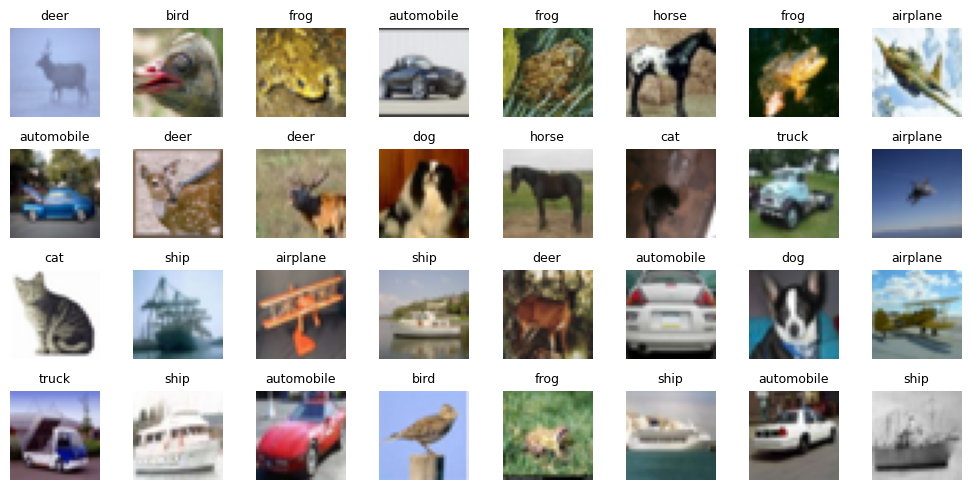

In [ ]:
plt.figure(figsize=(10, 5))
for i in range(32):
    plt.subplot(4, 8, i + 1)
    plt.imshow(images[i].permute(1, 2, 0))
    plt.title(classes[labels[i]], fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

---
# Task 4: Dataset Augmentation

Here I make all the suggested augmentations. I put them in groups so I can compare them in Task 5.

| Name | What it does |
|---|---|
| `none` | Only `ToTensor` and `Normalize` |
| `crop_flip` | `RandomCrop` with padding of 4 and `RandomHorizontalFlip` |
| `resized_crop` | `RandomResizedCrop` and `RandomHorizontalFlip` |
| `color_jitter` | `crop_flip` and `ColorJitter` |
| `rotation` | `crop_flip` and `RandomRotation` |
| `gaussian_noise` | `crop_flip` and Gaussian noise |
| `salt_pepper_noise` | `crop_flip` and salt and pepper noise |
| `trivial_cutout` | `crop_flip`, `TrivialAugmentWide` and Cutout |

`TrivialAugmentWide` applies one random operation with a random strength to each image. Cutout blanks a random 16x16 square.

**Normalization:** a pretrained network must get its inputs in the same range as during its original training, so I use the mean and standard deviation from its ImageNet training, not the ones from CIFAR-10. timm stores them with each model.

The dataset already gives PIL images, so `ToPILImage` is not needed in these pipelines. I use it below to turn a raw array into a PIL image for the pictures. `ToTensor` makes a tensor in CxHxW format.

**Test data:** the test images only get `ToTensor` and `Normalize`. They need the same normalization as the training images, but no random changes or noise.

In [7]:
FILL = (125, 123, 114)      # the average color, for pixels that become empty after moving the image


class Cutout:
    def __init__(self, size):
        self.size = size

    def __call__(self, x):
        h, w = x.shape[-2:]
        cy = int(torch.randint(h, (1,)))
        cx = int(torch.randint(w, (1,)))
        half = self.size // 2
        x[..., max(0, cy - half):min(h, cy + half), max(0, cx - half):min(w, cx + half)] = 0.0
        return x


class GaussianNoise:
    def __init__(self, std):
        self.std = std

    def __call__(self, x):
        return (x + torch.randn_like(x) * self.std).clamp(0, 1)


class SaltPepperNoise:
    def __init__(self, amount):
        self.amount = amount

    def __call__(self, x):
        random_values = torch.rand(x.shape[1:])
        x = x.clone()
        x[:, random_values < self.amount / 2] = 0.0
        x[:, random_values > 1 - self.amount / 2] = 1.0
        return x


def make_augmentations(mean, std):
    crop_flip = [T.RandomCrop(32, padding=4, fill=FILL), T.RandomHorizontalFlip()]
    to_tensor = [T.ToTensor(), T.Normalize(mean, std)]
    return {
        'none': T.Compose(to_tensor),
        'crop_flip': T.Compose(crop_flip + to_tensor),
        'resized_crop': T.Compose([T.RandomResizedCrop(32, scale=(0.6, 1.0)), T.RandomHorizontalFlip()] + to_tensor),
        'color_jitter': T.Compose(crop_flip + [T.ColorJitter(0.4, 0.4, 0.4, 0.1)] + to_tensor),
        'rotation': T.Compose(crop_flip + [T.RandomRotation(15, fill=FILL)] + to_tensor),
        'gaussian_noise': T.Compose(crop_flip + [T.ToTensor(), GaussianNoise(0.05), T.Normalize(mean, std)]),
        'salt_pepper_noise': T.Compose(crop_flip + [T.ToTensor(), SaltPepperNoise(0.05), T.Normalize(mean, std)]),
        'trivial_cutout': T.Compose(crop_flip + [T.TrivialAugmentWide(fill=FILL)] + to_tensor + [Cutout(16)]),
    }


# The mean and standard deviation that each pretrained model expects
def get_mean_std(model_name):
    if model_name == 'simple_cnn':
        return timm.data.IMAGENET_DEFAULT_MEAN, timm.data.IMAGENET_DEFAULT_STD
    config = timm.get_pretrained_cfg(model_name)
    return config.mean, config.std


mean, std = get_mean_std(FINAL_MODEL_NAME)
print('Mean:', mean, ' Standard deviation:', std)

Mean: (0.485, 0.456, 0.406)  Standard deviation: (0.229, 0.224, 0.225)


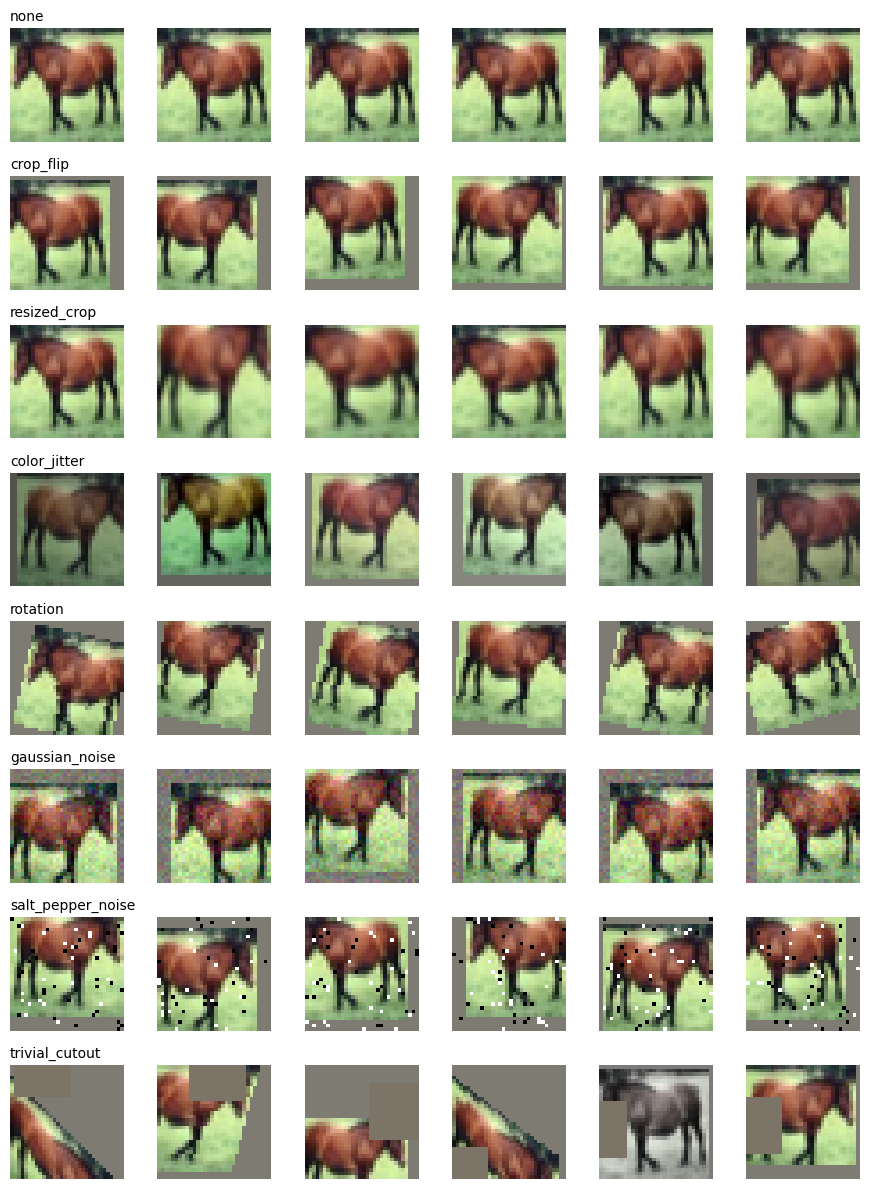

In [ ]:
augmentations = make_augmentations(mean, std)
sample_image = T.ToPILImage()(train_data.data[7])
mean_tensor = torch.tensor(mean).view(3, 1, 1)
std_tensor = torch.tensor(std).view(3, 1, 1)

plt.figure(figsize=(9, 12))
row = 0
for name, transform in augmentations.items():
    for column in range(6):
        augmented = transform(sample_image)
        augmented = (augmented * std_tensor + mean_tensor).clamp(0, 1)
        plt.subplot(len(augmentations), 6, row * 6 + column + 1)
        plt.imshow(augmented.permute(1, 2, 0))
        plt.axis('off')
        if column == 0:
            plt.title(name, fontsize=10, loc='left')
    row += 1
plt.tight_layout()
plt.show()

In [9]:
# use_validation=True:  10,000 training images become a validation set. The test set is not touched.
# use_validation=False: all 50,000 images are used for training and the test set is used for testing.
VALIDATION_IMAGES = 10000

def make_loaders(augmentation, batch_size, use_validation, model_name):
    transforms = make_augmentations(*get_mean_std(model_name))
    train_set = torchvision.datasets.CIFAR10(DATA_PATH, train=True, transform=transforms[augmentation])

    if use_validation:
        val_set = torchvision.datasets.CIFAR10(DATA_PATH, train=True, transform=transforms['none'])
        order = torch.randperm(len(train_set), generator=torch.Generator().manual_seed(0)).tolist()
        evaluation_set = Subset(val_set, order[:VALIDATION_IMAGES])
        train_set = Subset(train_set, order[VALIDATION_IMAGES:])
    else:
        evaluation_set = torchvision.datasets.CIFAR10(DATA_PATH, train=False, transform=transforms['none'])

    # timeout: stop with an error if a worker process hangs, instead of waiting forever
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, drop_last=True,
                              num_workers=NUM_WORKERS, pin_memory=True, generator=torch.Generator(),
                              persistent_workers=NUM_WORKERS > 0, timeout=600 if NUM_WORKERS > 0 else 0)

    # The test images need very little work, so the main process prepares them. Starting new
    # worker processes again and again from a program with many threads can make it hang.
    evaluation_loader = DataLoader(evaluation_set, batch_size=200, shuffle=False, pin_memory=True)
    return train_loader, evaluation_loader


train_loader, evaluation_loader = make_loaders('trivial_cutout', 128, False, FINAL_MODEL_NAME)
images, labels = next(iter(train_loader))
print('Images tensor size after augmentation:', images.shape)
print('Training batches:', len(train_loader), ' Test batches:', len(evaluation_loader))
print('Tensor size after the enlarging layer:', convnext_cifar10[0](images[:2]).shape)
del train_loader, evaluation_loader, convnext_cifar10

Images tensor size after augmentation: torch.Size([128, 3, 32, 32])
Training batches: 390  Test batches: 50
Tensor size after the enlarging layer: torch.Size([2, 3, 224, 224])


---
# Task 5: Training Function and Tuning Hyperparameters

`train_model` trains for all the epochs. It records the training loss and accuracy every epoch, and the test loss and accuracy every 2 epochs. `plot_history` draws the plots.

**Checkpoints:** a Kaggle session has a time limit. So during the final training, `train_model` saves a checkpoint every 5 epochs, and it stops by itself if the session is nearly out of time. If that happens, I attach the output of the session to a new session and run the notebook again, and the training continues from the checkpoint.

In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


CHECKPOINT_FILE = 'checkpoint.pth'
STOP_HOURS = 3.7       # the final training stops after this many hours in the session, so the notebook can finish


def find_saved_file(name):
    # Look in this folder first, then in the output of an earlier session attached as an input on Kaggle
    if os.path.exists(name):
        return name
    found = glob.glob('/kaggle/input/**/' + name, recursive=True)
    return found[0] if found else None


def save_checkpoint(model, ema_model, optimizer, scaler, step, epoch, history, settings):
    checkpoint = {'model': model.state_dict(), 'ema_model': ema_model.state_dict(),
                  'optimizer': optimizer.state_dict(), 'scaler': scaler.state_dict(),
                  'step': step, 'epoch': epoch, 'history': history, 'settings': settings,
                  'torch_rng': torch.get_rng_state(), 'cuda_rng': torch.cuda.get_rng_state_all()}
    # Save with a temporary name first, so a crash while saving can't damage the last good checkpoint
    torch.save(checkpoint, CHECKPOINT_FILE + '.tmp')
    os.replace(CHECKPOINT_FILE + '.tmp', CHECKPOINT_FILE)


def train_model(model, train_loader, test_loader, settings, final_run=False, checkpoint=None):
    model = model.to(device)
    ema_model = copy.deepcopy(model)

    # Split batches between the GPUs
    runner = nn.DataParallel(model) if NUM_GPUS > 1 else model
    ema_runner = nn.DataParallel(ema_model) if NUM_GPUS > 1 else ema_model

    decay_params = [p for p in model.parameters() if p.ndim > 1]
    other_params = [p for p in model.parameters() if p.ndim <= 1]
    optimizer = torch.optim.AdamW([{'params': decay_params, 'weight_decay': settings['weight_decay']},
                                   {'params': other_params, 'weight_decay': 0.0}], lr=settings['lr'])
    scaler = torch.amp.GradScaler('cuda')

    history = {'train_loss': [], 'train_acc': [], 'test_epoch': [], 'test_loss': [], 'test_acc': []}
    start = time.time()
    step = 0
    first_epoch = 1
    earlier_minutes = 0

    if checkpoint is not None:
        model.load_state_dict(checkpoint['model'])
        ema_model.load_state_dict(checkpoint['ema_model'])
        optimizer.load_state_dict(checkpoint['optimizer'])
        scaler.load_state_dict(checkpoint['scaler'])
        step = checkpoint['step']
        first_epoch = checkpoint['epoch'] + 1
        history = checkpoint['history']
        earlier_minutes = history['minutes']
        torch.set_rng_state(checkpoint['torch_rng'])
        torch.cuda.set_rng_state_all(checkpoint['cuda_rng'])

    for epoch in range(first_epoch, settings['epochs'] + 1):
        train_loader.generator.manual_seed(settings['seed'] * 100003 + epoch - 1)
        sam_start = settings['sam_start_epoch']
        use_sam = sam_start is not None and epoch > sam_start

        train_loss, train_acc, step = train_one_epoch(model, runner, ema_model, train_loader, optimizer, scaler,
                                                      settings, step, use_sam)
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)

        last_epoch = epoch == settings['epochs']
        out_of_time = final_run and time.time() - notebook_start > STOP_HOURS * 3600

        if epoch % 2 == 0 or last_epoch or out_of_time:
            test_loss, test_acc = test_model(ema_runner, test_loader)
            history['test_epoch'].append(epoch)
            history['test_loss'].append(test_loss)
            history['test_acc'].append(test_acc)
            history['minutes'] = earlier_minutes + (time.time() - start) / 60
            if final_run:
                print(f'epoch {epoch}/{settings["epochs"]}  train loss {train_loss:.4f}  train acc {train_acc:.2f}  '
                      f'test loss {test_loss:.4f}  test acc {test_acc:.2f}  '
                      f'time {history["minutes"]:.1f} min', flush=True)

        if final_run and (epoch % 5 == 0 or last_epoch or out_of_time):
            save_checkpoint(model, ema_model, optimizer, scaler, step, epoch, history, settings)

        if out_of_time and not last_epoch:
            print('Out of time for this session. The training continues from the checkpoint in a new session.', flush=True)
            break

    history['minutes'] = earlier_minutes + (time.time() - start) / 60
    return ema_model, history


def plot_history(history):
    train_epochs = range(1, len(history['train_loss']) + 1)
    plots = [('Training loss', train_epochs, history['train_loss'], 'Loss'),
             ('Test loss', history['test_epoch'], history['test_loss'], 'Loss'),
             ('Test accuracy', history['test_epoch'], history['test_acc'], 'Accuracy (%)')]

    plt.figure(figsize=(14, 4))
    for i, (title, x, y, y_label) in enumerate(plots):
        plt.subplot(1, 3, i + 1)
        plt.plot(x, y, linewidth=2)
        plt.margins(y=0.15)
        if 'loss' in title:
            plt.annotate(f'{y[-1]:.4f}', (x[-1], y[-1]), xytext=(-8, 12), textcoords='offset points', ha='right')
        else:
            plt.annotate(f'{y[-1]:.2f}%', (x[-1], y[-1]), xytext=(-8, -14), textcoords='offset points', ha='right')
        plt.title(title)
        plt.xlabel('Epoch')
        plt.ylabel(y_label)
        plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## Hyperparameter search

Fine-tuning a large network takes hours, so I can't try every combination. I tune **one setting at a time** using short runs, in this order:

1. Compare a few pretrained networks, with the small CNN as a baseline.
2. With ConvNeXt-Tiny, which is several times faster, try different values of the learning rate, weight decay, label smoothing and stochastic depth.
3. Compare the augmentations from Task 4.

**The data:** all the runs here use 40,000 images for training and 10,000 for validation. The test set is not used in the search.

**The starting values:** before writing this notebook I ran separate experiments to find a reasonable starting point. They showed that AdamW with a learning rate of 1e-4 and `trivial_cutout` worked well on these networks. So this search checks whether any other value is clearly better. I did not start from zero.

**How I choose:** a new value only replaces the current one if its validation accuracy is more than 0.1 points higher. With 10,000 images and an accuracy near 99%, the standard error of one score is about 0.1 points, so a smaller difference can be just noise.

**What I don't search:** I keep AdamW, gradient clipping at 5.0, the EMA window at 3% and the image size at 224x224. I don't search SAM either, because it makes training slower and short runs can't show its benefit. Rho = 0.05 is the value recommended in the SAM paper.

**Limits:** these are short runs with one seed, mostly on a smaller network, so they can reject bad values but they can't find the exact best value.

**Two sessions:** my first session of this notebook stopped responding during step 3, after 16 runs, with no error message. So this session loads the results of those 16 runs, copied from the log of the first session, and only trains the two runs that were left. Those 16 runs used the same code and settings, and the results are marked "from the earlier session" below. The likely reason for the hang was starting new data worker processes many times, so now the test images are prepared in the main process, and the training loader stops with an error if a worker hangs.

In [11]:
SEARCH_FILE = 'search_results.json'
search_results = []

# If an earlier session already finished some of the runs, load their results
saved_results = []
if find_saved_file(SEARCH_FILE):
    with open(find_saved_file(SEARCH_FILE)) as f:
        saved_results = json.load(f)

# The runs that my first session finished, copied from its log
def first_session_row(step, model, epochs, batch_size, val_acc, minutes, lr=1e-4, weight_decay=0.01,
                      label_smoothing=0.0, drop_path=0.0, augmentation='trivial_cutout'):
    return {'step': step, 'model': model, 'epochs': epochs, 'batch_size': batch_size, 'lr': lr, 'weight_decay': weight_decay,
            'label_smoothing': label_smoothing, 'drop_path': drop_path, 'augmentation': augmentation,
            'val_acc': val_acc, 'minutes': minutes}


TINY = 'convnext_tiny.fb_in22k'
saved_results += [
    first_session_row('model', 'simple_cnn', 3, 128, 66.48, 1.0, lr=1e-3),
    first_session_row('model', TINY, 3, 128, 98.35, 5.4),
    first_session_row('model', 'tf_efficientnetv2_m.in21k', 3, 128, 97.38, 12.6),
    first_session_row('model', 'convnext_base.fb_in22k', 3, 128, 99.22, 12.5),
    first_session_row('model', 'convnext_large.fb_in22k', 3, 64, 99.35, 27.6),
    first_session_row('lr', TINY, 4, 128, 98.58, 7.0),
    first_session_row('lr', TINY, 4, 128, 98.00, 7.0, lr=3e-5),
    first_session_row('lr', TINY, 4, 128, 98.43, 7.0, lr=3e-4),
    first_session_row('weight_decay', TINY, 4, 128, 98.52, 7.0, weight_decay=0.05),
    first_session_row('label_smoothing', TINY, 4, 128, 98.53, 7.0, label_smoothing=0.1),
    first_session_row('drop_path', TINY, 4, 128, 97.91, 7.2, drop_path=0.2),
    first_session_row('augmentation', TINY, 4, 128, 98.54, 7.0, augmentation='none'),
    first_session_row('augmentation', TINY, 4, 128, 98.64, 7.0, augmentation='crop_flip'),
    first_session_row('augmentation', TINY, 4, 128, 98.69, 7.0, augmentation='resized_crop'),
    first_session_row('augmentation', TINY, 4, 128, 98.53, 7.0, augmentation='color_jitter'),
    first_session_row('augmentation', TINY, 4, 128, 98.47, 7.0, augmentation='rotation'),
]


def run_experiment(step_name, settings):
    row = {'step': step_name, 'model': settings['model'], 'epochs': settings['epochs'], 'batch_size': settings['batch_size'],
           'lr': settings['lr'], 'weight_decay': settings['weight_decay'], 'label_smoothing': settings['label_smoothing'],
           'drop_path': settings['drop_path'], 'augmentation': settings['augmentation']}

    for saved in saved_results:
        if all(saved[key] == row[key] for key in row):
            search_results.append(saved)
            print(f'{step_name}: {settings[step_name]}  val acc {saved["val_acc"]:.2f}  (result from the earlier session)', flush=True)
            return saved['val_acc'], saved['minutes']

    set_seed(settings['seed'])
    model = build_model(settings['model'], settings['drop_path'])
    train_loader, val_loader = make_loaders(settings['augmentation'], settings['batch_size'], True, settings['model'])
    ema_model, history = train_model(model, train_loader, val_loader, settings)
    val_acc = history['test_acc'][-1]

    row['val_acc'] = val_acc
    row['minutes'] = round(history['minutes'], 1)
    search_results.append(row)
    with open(SEARCH_FILE, 'w') as f:
        json.dump(search_results, f)

    print(f'{step_name}: {settings[step_name]}  val acc {val_acc:.2f}  ({history["minutes"]:.1f} min)', flush=True)
    del model, ema_model, train_loader, val_loader
    torch.cuda.empty_cache()
    return val_acc, history['minutes']


MARGIN = 0.1          # a new value must be better than this many points
ARCH_EPOCHS = 3         # epochs for each architecture
SHORT_EPOCHS = 4        # epochs for each tuning run

start_settings = {'model': 'convnext_tiny.fb_in22k', 'seed': 1, 'epochs': SHORT_EPOCHS, 'warmup_epochs': 1,
                  'lr': 1e-4, 'weight_decay': 0.01, 'batch_size': 128, 'label_smoothing': 0.0,
                  'drop_path': 0.0, 'augmentation': 'trivial_cutout', 'sam_start_epoch': None}

### Step 1: Network architecture

All these runs use the same settings and the same number of epochs. The pretrained names show the dataset they were trained on: `in22k` and `in21k` mean ImageNet with about 21,000 classes.

In [12]:
arch_acc = {}
arch_minutes = {}

for name, batch_size in [('simple_cnn', 128), ('convnext_tiny.fb_in22k', 128), ('tf_efficientnetv2_m.in21k', 128),
                         ('convnext_base.fb_in22k', 128), ('convnext_large.fb_in22k', 64)]:
    settings = dict(start_settings)
    settings['model'] = name
    settings['epochs'] = ARCH_EPOCHS
    settings['batch_size'] = batch_size
    if name == 'simple_cnn':
        settings['lr'] = 1e-3       # random weights need a bigger learning rate than fine-tuning
    arch_acc[name], arch_minutes[name] = run_experiment('model', settings)

best_model = max(arch_acc, key=arch_acc.get)
print('Best architecture in the short runs:', best_model)

model: simple_cnn  val acc 66.48  (result from the earlier session)
model: convnext_tiny.fb_in22k  val acc 98.35  (result from the earlier session)
model: tf_efficientnetv2_m.in21k  val acc 97.38  (result from the earlier session)
model: convnext_base.fb_in22k  val acc 99.22  (result from the earlier session)
model: convnext_large.fb_in22k  val acc 99.35  (result from the earlier session)
Best architecture in the short runs: convnext_large.fb_in22k


### Step 2: Learning rate, weight decay, label smoothing and stochastic depth

Stochastic depth (`drop_path`) randomly skips whole blocks during training, as a regularizer.

In [13]:
search_space = {
    'lr': [3e-5, 1e-4, 3e-4],
    'weight_decay': [0.01, 0.05],
    'label_smoothing': [0.0, 0.1],
    'drop_path': [0.0, 0.2],
}

best_settings = dict(start_settings)
best_acc, _ = run_experiment('lr', best_settings)      # the starting values

for name, values in search_space.items():
    for value in values:
        if value == best_settings[name]:
            continue        # this one is already done
        trial = dict(best_settings)
        trial[name] = value
        acc, _ = run_experiment(name, trial)
        if acc > best_acc + MARGIN:
            best_settings = trial
            best_acc = acc

print('Best so far:', {name: best_settings[name] for name in search_space}, ' val acc', best_acc)

lr: 0.0001  val acc 98.58  (result from the earlier session)
lr: 3e-05  val acc 98.00  (result from the earlier session)
lr: 0.0003  val acc 98.43  (result from the earlier session)
weight_decay: 0.05  val acc 98.52  (result from the earlier session)
label_smoothing: 0.1  val acc 98.53  (result from the earlier session)
drop_path: 0.2  val acc 97.91  (result from the earlier session)
Best so far: {'lr': 0.0001, 'weight_decay': 0.01, 'label_smoothing': 0.0, 'drop_path': 0.0}  val acc 98.58


### Step 3: Data augmentation

In [14]:
aug_acc = {best_settings['augmentation']: best_acc}

for name in make_augmentations(mean, std):
    if name not in aug_acc:
        trial = dict(best_settings)
        trial['augmentation'] = name
        aug_acc[name], _ = run_experiment('augmentation', trial)

best_augmentation = max(aug_acc, key=aug_acc.get)
if aug_acc[best_augmentation] <= best_acc + MARGIN:
    best_augmentation = best_settings['augmentation']     # not clearly better than the current one
best_settings['augmentation'] = best_augmentation
print('Best augmentation in the short runs:', best_augmentation)

augmentation: none  val acc 98.54  (result from the earlier session)
augmentation: crop_flip  val acc 98.64  (result from the earlier session)
augmentation: resized_crop  val acc 98.69  (result from the earlier session)
augmentation: color_jitter  val acc 98.53  (result from the earlier session)
augmentation: rotation  val acc 98.47  (result from the earlier session)


model.safetensors: reconstructing file:   0%|          |  0.00B /  178MB            

model.safetensors: downloading bytes:           |  0.00B            

augmentation: gaussian_noise  val acc 97.74  (7.3 min)
augmentation: salt_pepper_noise  val acc 98.57  (7.1 min)
Best augmentation in the short runs: resized_crop


### All the search results

In [15]:
results_table = pd.DataFrame(search_results)
results_table

,step,model,epochs,batch_size,lr,weight_decay,label_smoothing,drop_path,augmentation,val_acc,minutes
0,model,simple_cnn,3,128,0.00100,0.01,0.0,0.0,trivial_cutout,66.48,1.0
1,model,convnext_tiny.fb_in22k,3,128,0.00010,0.01,0.0,0.0,trivial_cutout,98.35,5.4
2,model,tf_efficientnetv2_m.in21k,3,128,0.00010,0.01,0.0,0.0,trivial_cutout,97.38,12.6
3,model,convnext_base.fb_in22k,3,128,0.00010,0.01,0.0,0.0,trivial_cutout,99.22,12.5
4,model,convnext_large.fb_in22k,3,64,0.00010,0.01,0.0,0.0,trivial_cutout,99.35,27.6
5,lr,convnext_tiny.fb_in22k,4,128,0.00010,0.01,0.0,0.0,trivial_cutout,98.58,7.0
6,lr,convnext_tiny.fb_in22k,4,128,0.00003,0.01,0.0,0.0,trivial_cutout,98.00,7.0
7,lr,convnext_tiny.fb_in22k,4,128,0.00030,0.01,0.0,0.0,trivial_cutout,98.43,7.0
8,weight_decay,convnext_tiny.fb_in22k,4,128,0.00010,0.05,0.0,0.0,trivial_cutout,98.52,7.0
9,label_smoothing,convnext_tiny.fb_in22k,4,128,0.00010,0.01,0.1,0.0,trivial_cutout,98.53,7.0


## The final model

The final model uses the pretrained network and settings I chose from my separate experiments, which also tested them on the larger networks. In runs of 8 epochs on 40,000 images with `trivial_cutout`, the validation accuracy was 99.42% for ConvNeXt-Large, 99.33% for ConvNeXt-Base and 99.38% for ConvNeXt-Base with label smoothing and SAM. These differences are close to the noise, so they suggest these choices but do not prove them. The table below shows if the search in this notebook agrees with them.

The final model trains on all 50,000 training images. The number of epochs depends on the time I have left. The test set is used only to measure the final model, and I report the score of the last epoch, not the best epoch.

If there is a checkpoint from an earlier session, the settings come from the checkpoint, because the learning rate schedule depends on the total number of epochs.

In [16]:
TIME_LIMIT_HOURS = 3.55      # the whole notebook should finish in this time

saved_file = find_saved_file(CHECKPOINT_FILE)

if saved_file:
    checkpoint = torch.load(saved_file, map_location='cpu')
    final_settings = checkpoint['settings']
    print('Found a checkpoint at epoch', checkpoint['epoch'], 'of', final_settings['epochs'])
else:
    checkpoint = None

    # Decide the number of epochs from the speed of the same network in step 1 (it had 40,000 training images)
    seconds_per_epoch = arch_minutes[FINAL_MODEL_NAME] * 60 / ARCH_EPOCHS * 50000 / 40000
    average_seconds = seconds_per_epoch * (0.85 + 0.15 * 2)
    seconds_left = TIME_LIMIT_HOURS * 3600 - (time.time() - notebook_start) - 15 * 60

    final_epochs = int(seconds_left / average_seconds)
    final_epochs = min(max(final_epochs, 8), 60)
    print(f'{seconds_per_epoch:.0f} seconds per epoch, {seconds_left / 3600:.1f} hours left, so {final_epochs} epochs')

    final_settings = {'model': FINAL_MODEL_NAME, 'seed': 1, 'epochs': final_epochs, 'warmup_epochs': 1,
                      'lr': 1e-4, 'weight_decay': 0.01, 'batch_size': 64, 'label_smoothing': 0.1,
                      'drop_path': 0.0, 'augmentation': 'trivial_cutout', 'sam_start_epoch': round(0.85 * final_epochs)}

comparison = [{'setting': 'model', 'search result': best_model, 'final model': final_settings['model']}]
for name in list(search_space) + ['augmentation']:
    comparison.append({'setting': name, 'search result': best_settings[name], 'final model': final_settings[name]})
comparison = pd.DataFrame(comparison)
comparison['same'] = comparison['search result'] == comparison['final model']
comparison

690 seconds per epoch, 3.0 hours left, so 13 epochs


,setting,search result,final model,same
0,model,convnext_large.fb_in22k,convnext_large.fb_in22k,True
1,lr,0.0001,0.0001,True
2,weight_decay,0.01,0.01,True
3,label_smoothing,0.0,0.1,False
4,drop_path,0.0,0.0,True
5,augmentation,resized_crop,trivial_cutout,False


In [17]:
set_seed(final_settings['seed'])
final_network = build_model(final_settings['model'], final_settings['drop_path'])
train_loader, test_loader = make_loaders(final_settings['augmentation'], final_settings['batch_size'], False, final_settings['model'])

final_model, history = train_model(final_network, train_loader, test_loader, final_settings, final_run=True, checkpoint=checkpoint)

finished = len(history['train_loss']) == final_settings['epochs']
print(f'Training took {history["minutes"] / 60:.2f} hours')
print('Finished all the epochs:', finished)

epoch 2/13  train loss 0.7066  train acc 91.11  test loss 0.1168  test acc 99.24  time 22.9 min
epoch 4/13  train loss 0.6539  train acc 93.12  test loss 0.1147  test acc 99.28  time 45.6 min
epoch 6/13  train loss 0.6285  train acc 94.24  test loss 0.1137  test acc 99.31  time 68.3 min
epoch 8/13  train loss 0.6064  train acc 95.31  test loss 0.1144  test acc 99.29  time 91.0 min
epoch 10/13  train loss 0.5963  train acc 95.69  test loss 0.1135  test acc 99.35  time 113.6 min
epoch 12/13  train loss 0.5885  train acc 96.08  test loss 0.1135  test acc 99.37  time 146.6 min
epoch 13/13  train loss 0.5878  train acc 96.17  test loss 0.1123  test acc 99.36  time 168.4 min
Training took 2.81 hours
Finished all the epochs: True


## Results

The training loss includes label smoothing and uses augmented images, and the test loss has neither of these. So the two are not measured in the same way.

The accuracy here is from one network without test-time augmentation.

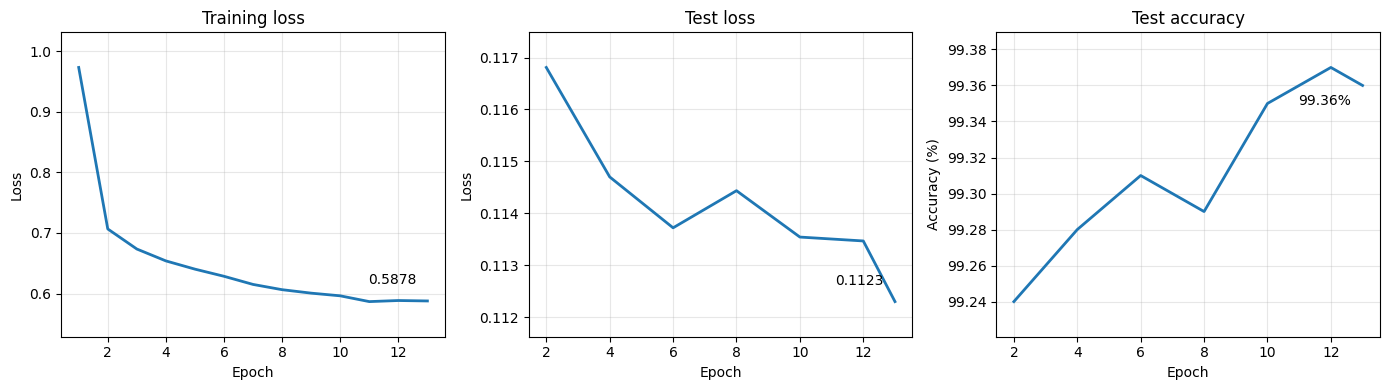

In [18]:
plot_history(history)

In [19]:
if not finished:
    print('THE TRAINING IS NOT FINISHED. These numbers are from epoch', len(history['train_loss']), 'of', final_settings['epochs'])
print('Final train loss:', round(history['train_loss'][-1], 4))
print('Final test loss:', round(history['test_loss'][-1], 4))
print('Final test accuracy:', history['test_acc'][-1], '%')
print('Test accuracy of my best network trained from random weights (WRN-28-10):', 97.60, '%')
print()
print('Best design:')
print('Network:', final_settings['model'], 'with', sum(p.numel() for p in final_model.parameters()), 'parameters, pretrained on ImageNet-22k')
print('Epochs:', final_settings['epochs'], ' Batch size:', final_settings['batch_size'])
print('Optimizer: AdamW, learning rate', final_settings['lr'], ' weight decay', final_settings['weight_decay'])
print('Schedule:', final_settings['warmup_epochs'], 'warmup epoch, then cosine')
print('Label smoothing:', final_settings['label_smoothing'], ' Stochastic depth:', final_settings['drop_path'])
print('Augmentation:', final_settings['augmentation'])
print('SAM from epoch:', final_settings['sam_start_epoch'], ' EMA window 3% of the steps, gradient clipping 5.0')

Final train loss: 0.5878
Final test loss: 0.1123
Final test accuracy: 99.36 %
Test accuracy of my best network trained from random weights (WRN-28-10): 97.6 %

Best design:
Network: convnext_large.fb_in22k with 196245706 parameters, pretrained on ImageNet-22k
Epochs: 13  Batch size: 64
Optimizer: AdamW, learning rate 0.0001  weight decay 0.01
Schedule: 1 warmup epoch, then cosine
Label smoothing: 0.1  Stochastic depth: 0.0
Augmentation: trivial_cutout
SAM from epoch: 11  EMA window 3% of the steps, gradient clipping 5.0


---
# Task 6: Save the Model and Source Code

I save the final weights, load them again into a new model and test it to check that the file is correct. Then I save the search results, the training history and the source code. When the training is finished I delete the checkpoint, because it is large and is only needed to continue training.

In [20]:
torch.save(final_model.state_dict(), 'convnext_cifar10.pth')

loaded_model = build_model(final_settings['model'], final_settings['drop_path']).to(device)
loaded_model.load_state_dict(torch.load('convnext_cifar10.pth', map_location=device))
test_loss, test_acc = test_model(loaded_model, test_loader)
print('Test accuracy of the saved model:', test_acc, '%')

results_table.to_csv('search_results.csv', index=False)
with open('training_history.json', 'w') as f:
    json.dump(history, f)

if finished and os.path.exists(CHECKPOINT_FILE):
    os.remove(CHECKPOINT_FILE)

Test accuracy of the saved model: 99.36 %


In [21]:
# Save the Python source code of this notebook
!jupyter nbconvert --to python __notebook__.ipynb --output cifar10_transfer_learning

print('Total time in this session:', round((time.time() - notebook_start) / 3600, 2), 'hours')
print(os.listdir('.'))

/usr/local/lib/python3.13/dist-packages/mistune.py:435: SyntaxWarning: invalid escape sequence '\|'
  cells[i][c] = re.sub('\\\\\|', '|', cell)
/usr/local/lib/python3.13/dist-packages/nbconvert/filters/filter_links.py:36: SyntaxWarning: invalid escape sequence '\_'
  text = re.sub(r'_', '\_', text) # Escape underscores in display text
[NbConvertApp] Converting notebook __notebook__.ipynb to python
[NbConvertApp] Writing 41035 bytes to cifar10_transfer_learning.py
Total time in this session: 3.08 hours
['convnext_cifar10.pth', 'search_results.json', 'search_results.csv', '__notebook__.ipynb', 'cifar10_transfer_learning.py', 'training_history.json']


In [22]:
# Kaggle's download command does not give the notebook with its outputs, so I save a copy of it here.
# Kaggle keeps __notebook__.ipynb up to date during the run. The output of this last cell is not in the copy.
import nbformat

if os.path.exists('__notebook__.ipynb'):
    for attempt in range(5):
        try:
            executed = nbformat.read('__notebook__.ipynb', as_version=4)
            break
        except Exception:
            time.sleep(2)
    nbformat.write(executed, 'cifar10_transfer_learning_executed.ipynb')